In [1]:
# Imports
import torch
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

import os
import random 
import matplotlib.pyplot as plt
from collections import defaultdict

# **1. Assembling the joint dataset**

In [2]:
transform = T.ToTensor() # Converts to Torch Tensor (C, H, W) so it can be later trained on

mnist = torchvision.datasets.MNIST(root='./data', download=True, transform=transform)  # Note this is only the 'training' data
svhn = torchvision.datasets.SVHN(root='./data', download=True, transform=transform)    # Note this is only the 'training' data

print(len(mnist))
print(len(svhn))

60000
73257


Get the indices per label of each dataset.

In [3]:
mnist_indices = defaultdict(list)
svhn_indices = defaultdict(list)

for i, label in enumerate(mnist.targets):
    mnist_indices[int(label)].append(i)

for i, label in enumerate(svhn.labels):
    svhn_indices[label].append(i)

print(mnist_indices[0])
print(svhn_indices[0])

[1, 21, 34, 37, 51, 56, 63, 68, 69, 75, 81, 88, 95, 108, 114, 118, 119, 121, 156, 169, 192, 206, 209, 210, 216, 229, 232, 234, 246, 249, 260, 283, 293, 296, 303, 320, 326, 359, 399, 427, 429, 435, 440, 451, 453, 458, 462, 464, 473, 489, 519, 524, 526, 527, 542, 577, 582, 596, 603, 612, 633, 639, 656, 662, 666, 667, 668, 669, 689, 702, 709, 712, 733, 743, 745, 776, 781, 787, 790, 818, 825, 849, 859, 860, 869, 872, 889, 903, 927, 943, 949, 952, 957, 965, 979, 984, 997, 1000, 1015, 1018, 1028, 1029, 1040, 1046, 1049, 1076, 1078, 1090, 1093, 1102, 1107, 1128, 1137, 1152, 1168, 1179, 1195, 1209, 1268, 1304, 1310, 1346, 1349, 1359, 1363, 1367, 1368, 1371, 1372, 1377, 1386, 1387, 1403, 1423, 1443, 1454, 1471, 1479, 1489, 1495, 1501, 1502, 1512, 1517, 1530, 1532, 1571, 1578, 1590, 1596, 1600, 1605, 1606, 1625, 1626, 1645, 1664, 1678, 1682, 1701, 1709, 1712, 1723, 1725, 1729, 1742, 1769, 1771, 1775, 1796, 1797, 1798, 1819, 1828, 1837, 1857, 1868, 1876, 1877, 1897, 1904, 1907, 1916, 1926, 1927, 

Calculating the number of pairs per number.

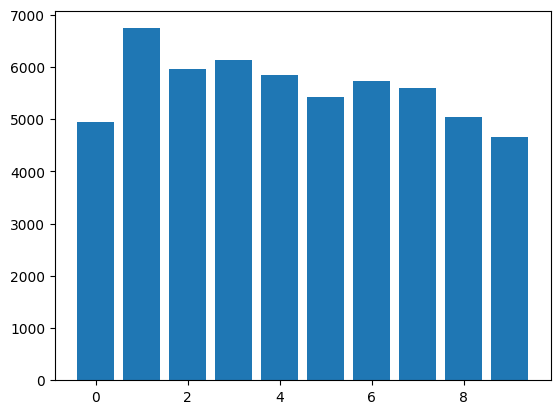

In [4]:
n_pairs = {
    digit: min(len(mnist_indices[digit]), len(svhn_indices[digit]))
    for digit in range(10)
}

plt.bar(n_pairs.keys(), n_pairs.values())
plt.show()

We decided not to balance the classes so far, since there are no big differences. Now we combine the datasets into tuples of indexes and their shared label.

In [5]:
pairs = []

for digit in range(10):
    mnist_idx = mnist_indices[digit].copy()
    svhn_idx = svhn_indices[digit].copy()

    # Shuffle to avoid bias
    random.shuffle(mnist_idx)
    random.shuffle(svhn_idx)

    n = n_pairs[digit]

    for mnist_idx, svhn_idx in zip(mnist_idx[:n], svhn_idx[:n]):
        pairs.append((mnist_idx, svhn_idx, digit))

print(pairs)

[(49059, 50648, 0), (45853, 35473, 0), (3262, 67161, 0), (15108, 38124, 0), (42245, 70754, 0), (46303, 35458, 0), (10781, 3460, 0), (51638, 41810, 0), (57542, 9380, 0), (23172, 41397, 0), (2396, 56806, 0), (1678, 42412, 0), (55991, 60892, 0), (10221, 63072, 0), (39789, 62888, 0), (1682, 50204, 0), (8249, 34832, 0), (19772, 4436, 0), (4218, 61261, 0), (13098, 47660, 0), (27462, 44543, 0), (3396, 13710, 0), (28816, 69159, 0), (18563, 19976, 0), (35620, 62155, 0), (1769, 47125, 0), (22657, 44999, 0), (27620, 37868, 0), (8369, 3079, 0), (38873, 29061, 0), (17508, 8576, 0), (4009, 71407, 0), (25803, 3447, 0), (25325, 43363, 0), (27477, 25720, 0), (1152, 57995, 0), (39422, 26901, 0), (52673, 3537, 0), (4849, 25256, 0), (51122, 11705, 0), (6607, 3335, 0), (44551, 40660, 0), (14971, 47555, 0), (9310, 16085, 0), (18921, 35548, 0), (46007, 51136, 0), (21560, 20561, 0), (7858, 56705, 0), (10625, 65424, 0), (35488, 6107, 0), (22202, 49192, 0), (42764, 44237, 0), (5468, 55874, 0), (26820, 46423, 0)

Now we create a combained pytorch dataset with both images and their label.

In [6]:
class CombinedDataset(Dataset):
    def __init__(self, mnist, svhn, pairs):
        self.mnist = mnist
        self.svhn = svhn
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        mnist_idx, svhn_idx, label = self.pairs[idx]

        img_mnist, _ = self.mnist[mnist_idx]
        img_svhn, _ = self.svhn[svhn_idx]

        return img_mnist, img_svhn, label

Label: 0


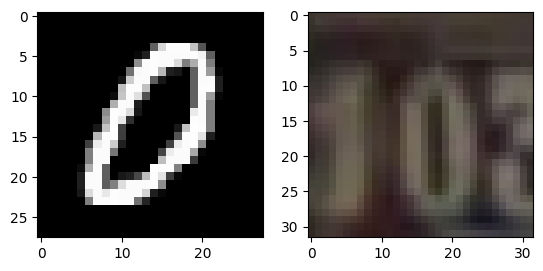

In [7]:
combined = CombinedDataset(mnist, svhn, pairs)

img_mnist, img_svhn, label = combined[0]
print('Label:', label)
plt.subplot(1, 2, 1)
plt.imshow(img_mnist.squeeze(), cmap = 'gray')
plt.subplot(1, 2, 2)
plt.imshow(img_svhn.permute(1,2,0))
plt.show()

In [8]:
img_mnist.shape

torch.Size([1, 28, 28])

In [ ]:
# Initializing the corresponding classes
from Nets import Encoder, Decoder, multiviewVAE
from architecture import mnist_encoder_conv_stack,mnist_decoder_conv_stack, shvn_decoder_conv_stack, shvn_encoder_conv_stack, encoder_linear_stack, decoder_linear_stack

latent_dim = 20

# Initializing encoder
encoder1 = Encoder(
    latent_dim, mnist_encoder_conv_stack(), encoder_linear_stack(latent_dim)
)
encoder2 = Encoder(
    latent_dim, shvn_encoder_conv_stack(), encoder_linear_stack(latent_dim)
)

# Initializing decoder
decoder1 = Decoder(
    mnist_decoder_conv_stack(),
    decoder_linear_stack(latent_dim),
    channels=256,
    height=1,
    width=1,
)
decoder2 = Decoder(
    shvn_decoder_conv_stack(),
    decoder_linear_stack(latent_dim),
    channels=256,
    height=1,
    width=1,
)

# Initializing multi-viewVAE
vae = multiviewVAE(
    encoder1=encoder1,
    encoder2=encoder2,
    decoder1=decoder1,
    decoder2=decoder2,
    var_x1=0.1, # May be adjusted depending on if we prioritize KL or not
    var_x2=0.1,
)


In [10]:
# Training Loop
dataloader = DataLoader(combined, batch_size=128, shuffle=True)

history = vae.train_loop(dataloader, lr=1e-3, epochs=20)

Epoch 1 | ELBO loss: -150.3363903291133 |Log-Likelihood 314.4015339045427 | KL1 1.8622925577977998 | KL2 11.86646193453028 
Epoch 2 | ELBO loss: -234.3462996080959 |Log-Likelihood 486.54570024703247 | KL1 2.345986347806752 | KL2 15.507112179367308 
Epoch 3 | ELBO loss: -254.3617465425461 |Log-Likelihood 530.1077664664232 | KL1 2.0913996930002896 | KL2 19.292872917679286 
Epoch 4 | ELBO loss: -262.4499491559074 |Log-Likelihood 548.2448968213891 | KL1 2.0337995331488328 | KL2 21.311197319986608 
Epoch 5 | ELBO loss: -266.76926573316706 |Log-Likelihood 557.3322379909507 | KL1 1.9846954294109127 | KL2 21.809014300822124 
Epoch 6 | ELBO loss: -271.2738666925452 |Log-Likelihood 567.3867569143517 | KL1 1.9610520359595436 | KL2 22.877970045954328 
Epoch 7 | ELBO loss: -274.5299272819641 |Log-Likelihood 574.4447546331106 | KL1 1.8961932789491902 | KL2 23.488708943603793 
Epoch 8 | ELBO loss: -276.4379083377082 |Log-Likelihood 578.4211772666705 | KL1 1.7360711786089835 | KL2 23.80928975411591 
E

In [11]:
# Saving model weights
os.makedirs("./checkpoints", exist_ok=True)
weight_path = "./checkpoints/multiview_vae.pth"
torch.save(vae.state_dict(), weight_path)

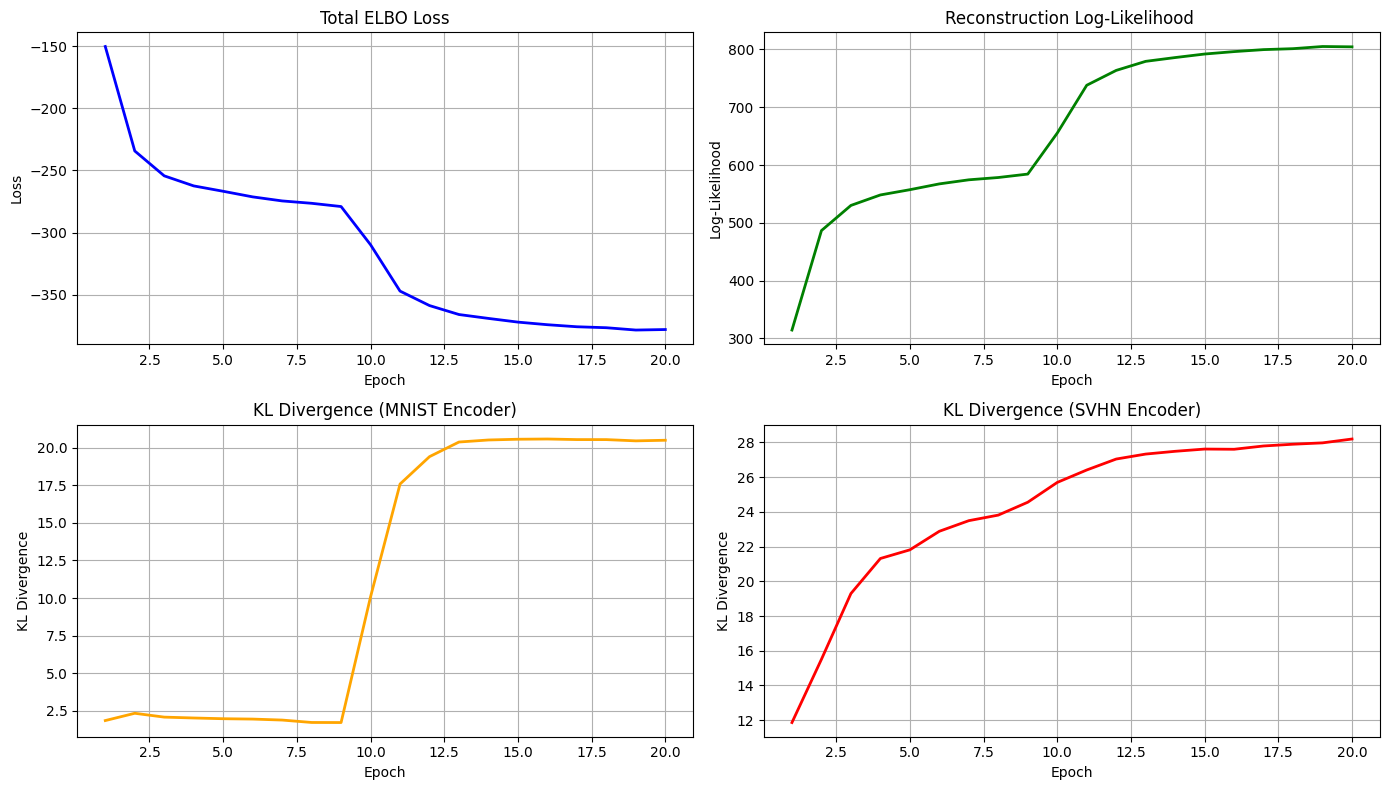

In [12]:
# Plotting training losses
epochs_range = range(1, len(history["elbo"]) + 1)

plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.plot(epochs_range, history["elbo"], color="blue", linewidth=2)
plt.title("Total ELBO Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(epochs_range, history["rec"], color="green", linewidth=2)
plt.title("Reconstruction Log-Likelihood ")
plt.xlabel("Epoch")
plt.ylabel("Log-Likelihood")
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(epochs_range, history["kl1"], color="orange", linewidth=2)
plt.title("KL Divergence (MNIST Encoder)")
plt.xlabel("Epoch")
plt.ylabel("KL Divergence")
plt.grid(True)

plt.subplot(2, 2, 4)
plt.plot(epochs_range, history["kl2"], color="red", linewidth=2)
plt.title("KL Divergence (SVHN Encoder)")
plt.xlabel("Epoch")
plt.ylabel("KL Divergence")
plt.grid(True)

plt.tight_layout()
plt.show()